# 02 · EDA and feature engineering (Unit II)

Figures are produced by `python -m src.eda`. Written findings: `docs/eda_findings.md`.

In [1]:
# Make the project folder importable (notebooks live in notebooks/)
import sys, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from config import project_config as cfg
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
from src.data_loader import load_hour_data
from src import eda
df = eda.add_readable_columns(load_hour_data())
print('Skewness of cnt:', round(df['cnt'].skew(), 2))

Skewness of cnt: 1.28


## Univariate and time patterns

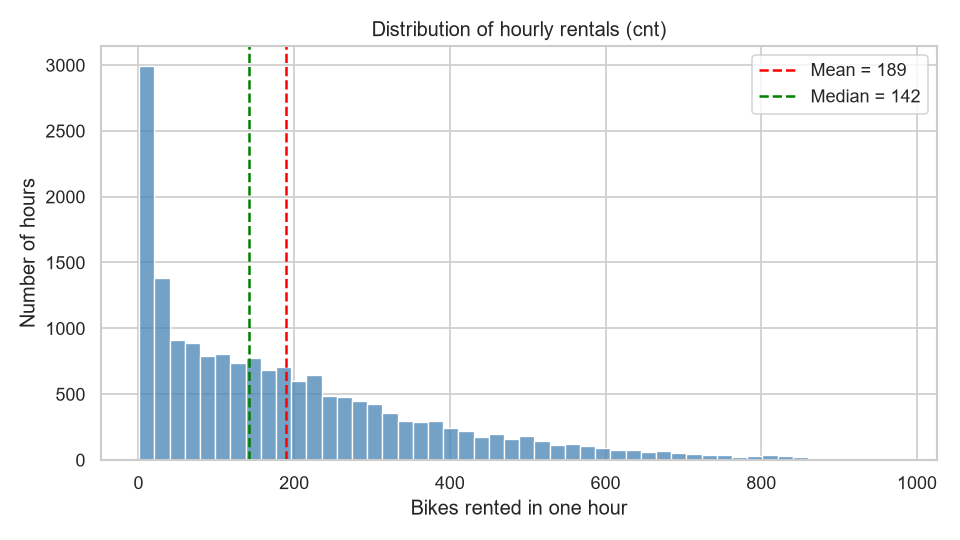

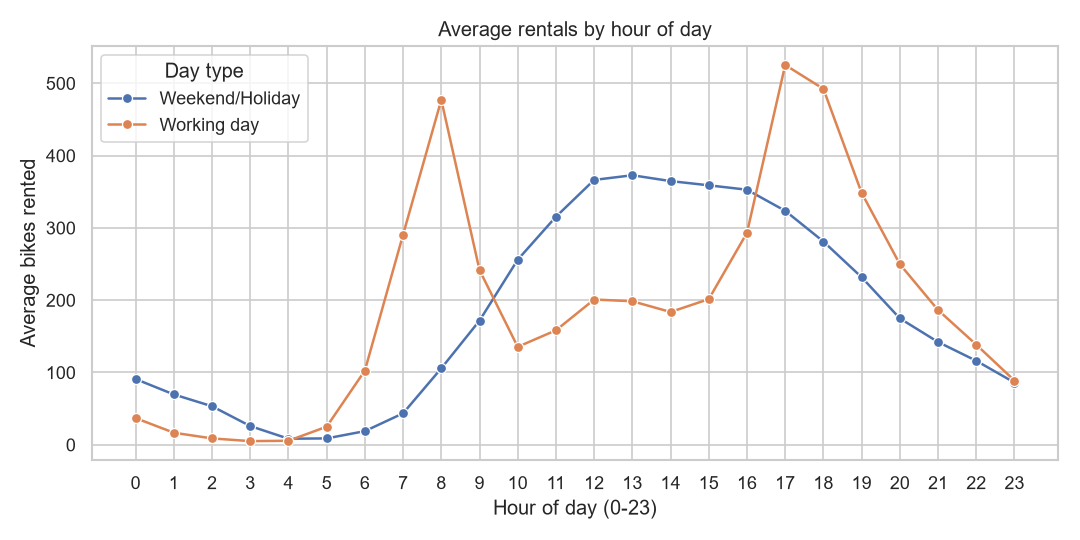

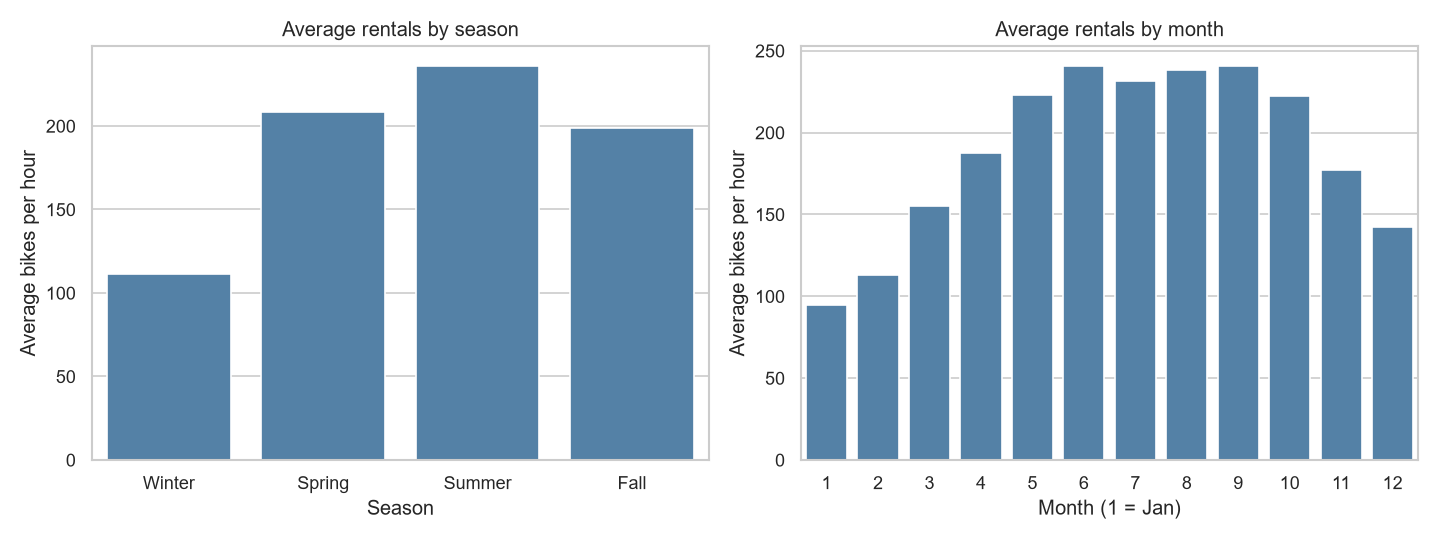

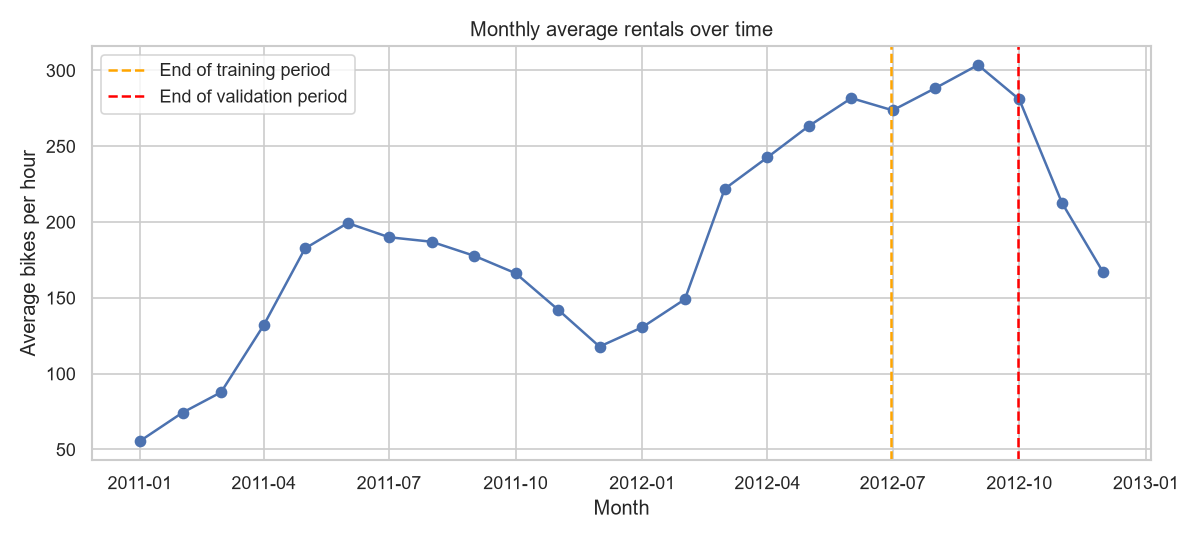

In [3]:
for name in ['01_target_distribution', '02_hourly_pattern_by_daytype', '03_season_and_month', '04_trend_over_time']:
    display(Image(filename=str(cfg.FIGURES_DIR / f'{name}.png')))

## Weather, correlation (multivariate) and outliers

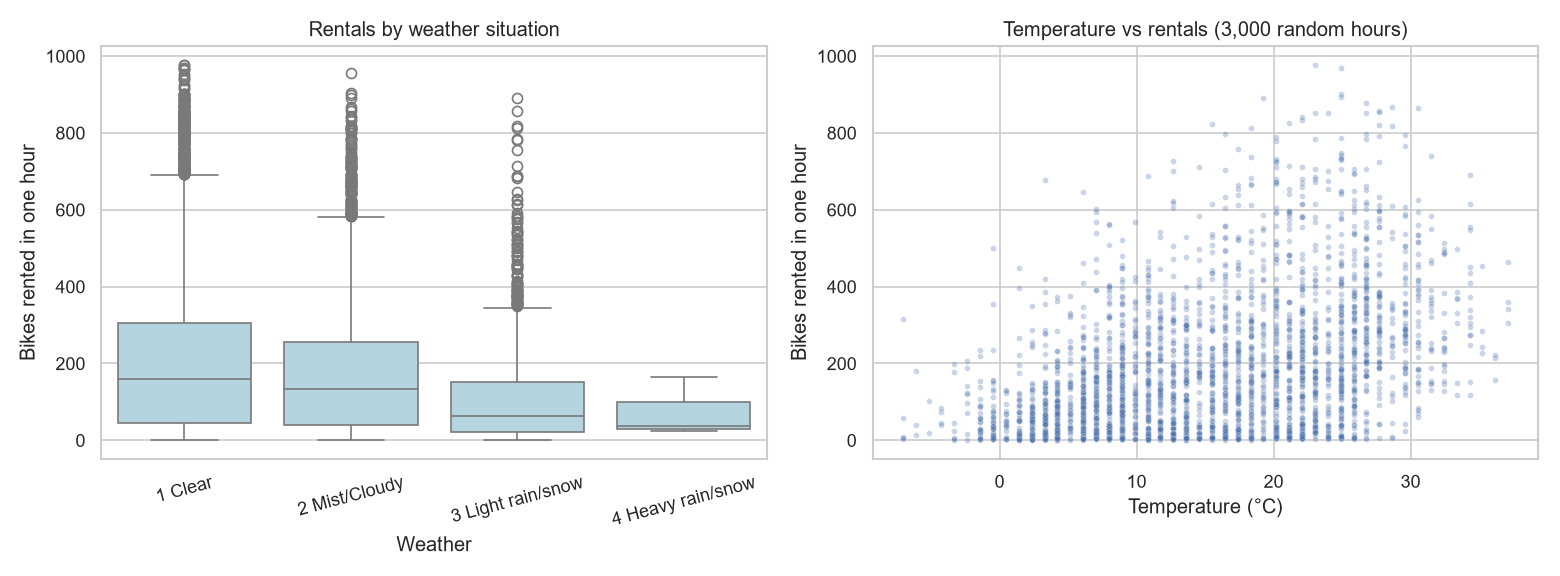

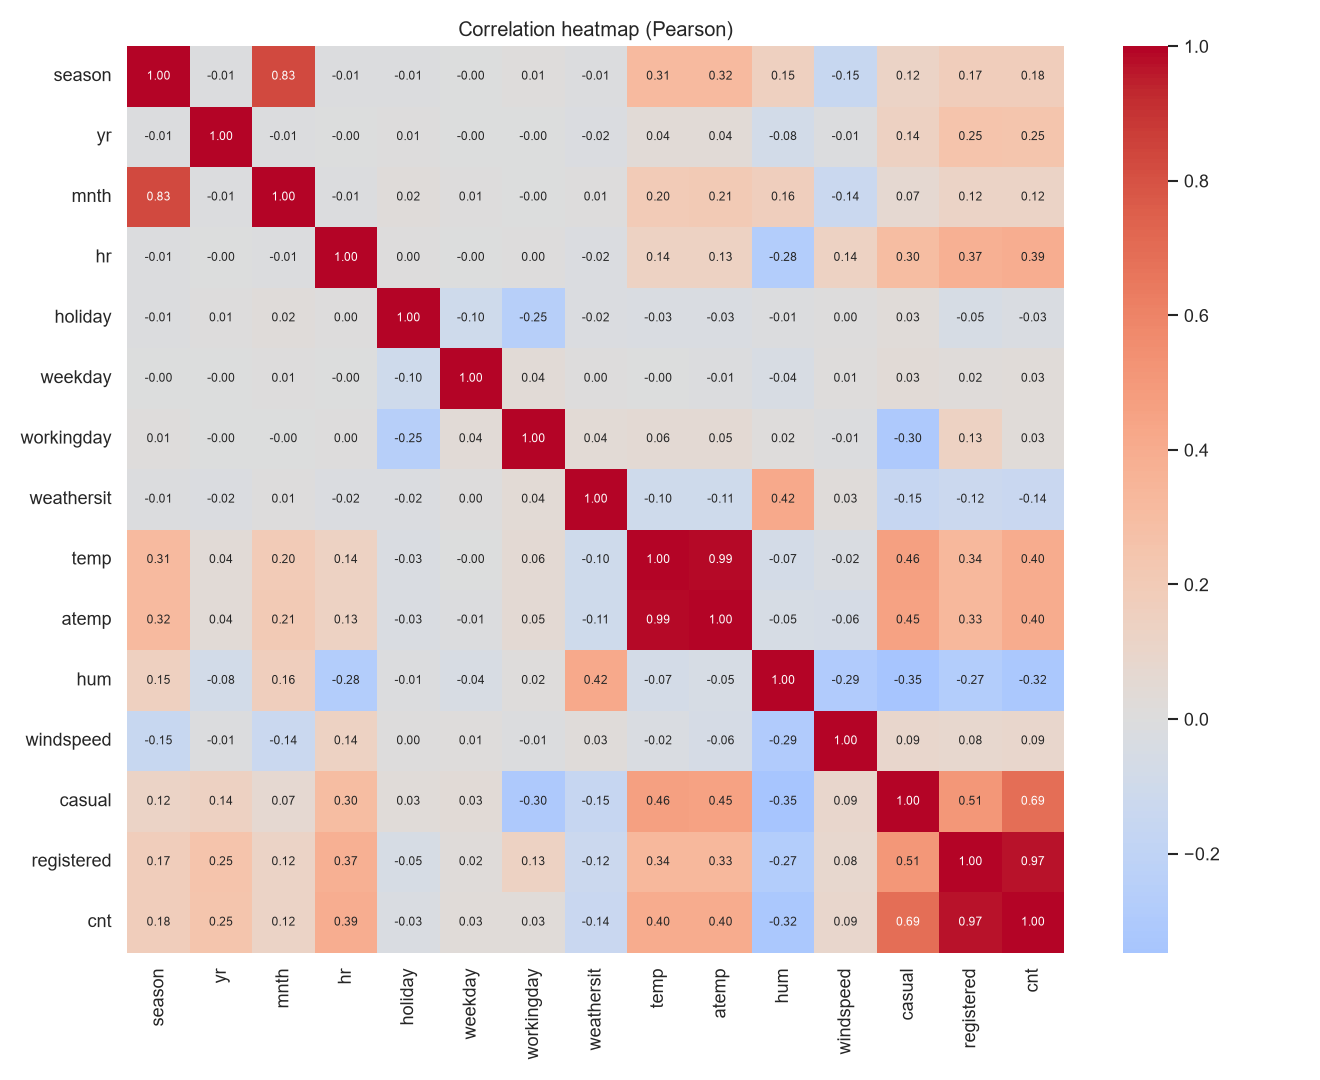

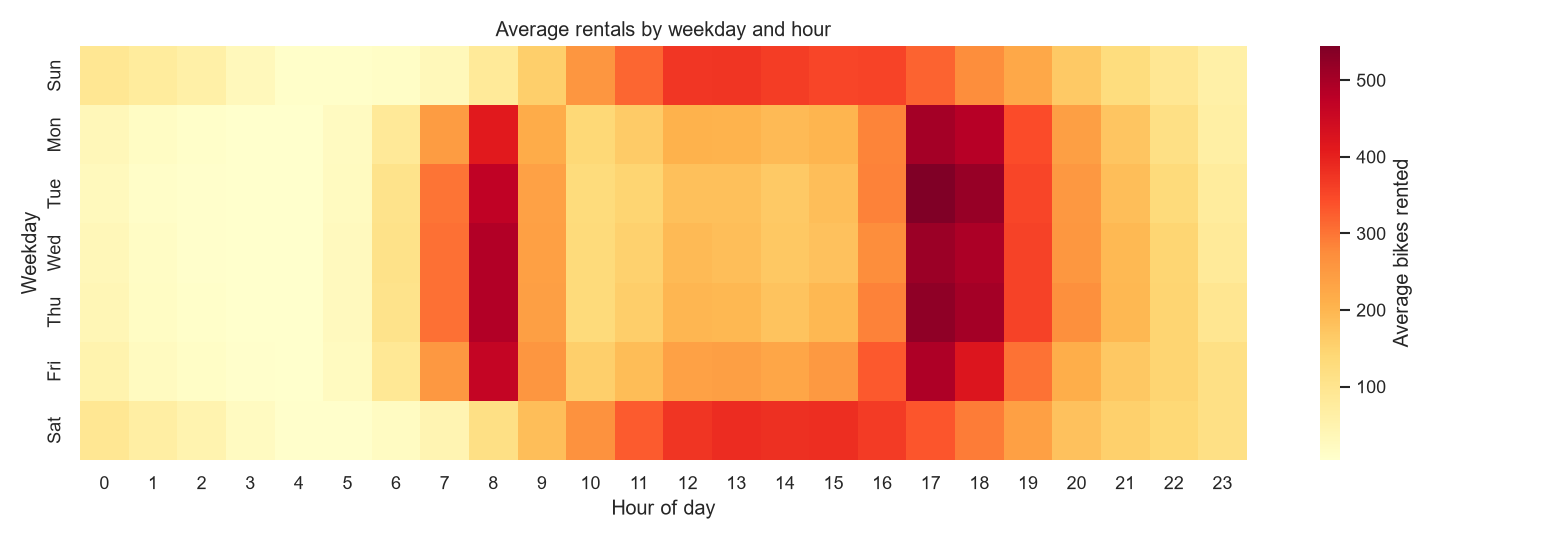

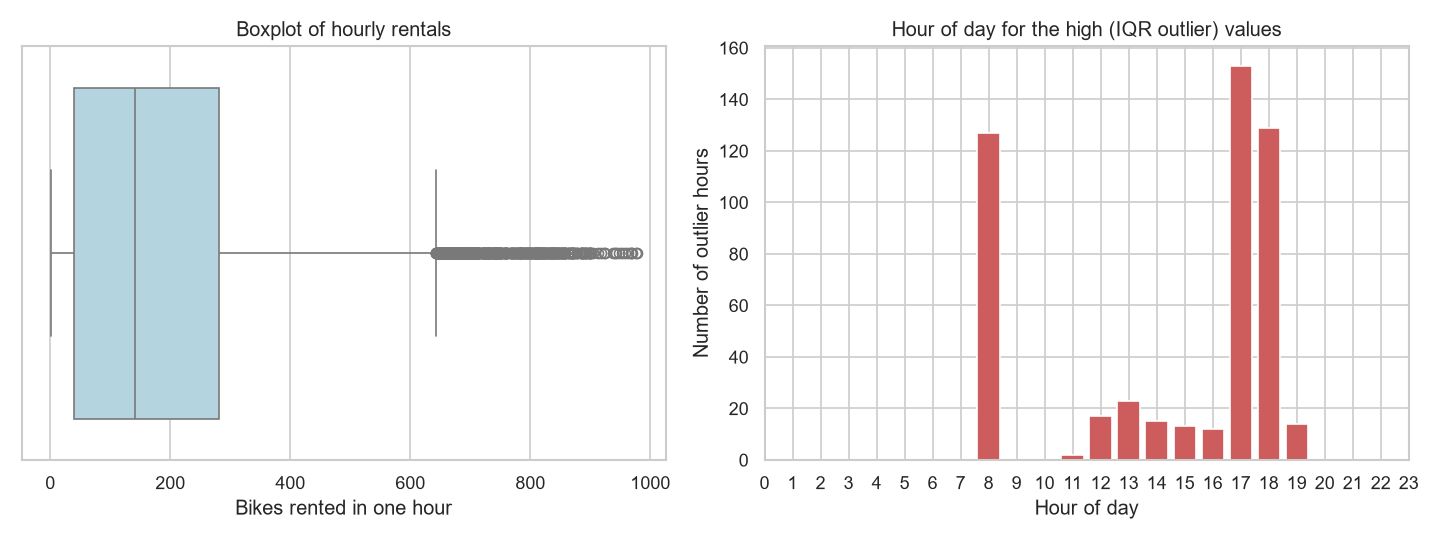

In [4]:
for name in ['05_weather_and_temperature', '06_correlation_heatmap', '07_weekday_hour_heatmap', '08_outliers']:
    display(Image(filename=str(cfg.FIGURES_DIR / f'{name}.png')))

## Data leakage check
`casual` and `registered` add up exactly to `cnt`, so they must never be inputs.

In [5]:
print('cnt == casual + registered for every row:', (df['casual'] + df['registered'] == df['cnt']).all())
print(df[['casual', 'registered', 'temp', 'atemp', 'hr', 'hum', 'cnt']].corr()['cnt'].round(3).to_string())
from src.feature_engineering import ALL_FEATURES
print('Leakage columns in model features:', [c for c in cfg.LEAKAGE_COLUMNS if c in ALL_FEATURES])

cnt == casual + registered for every row: True
casual        0.695
registered    0.972
temp          0.405
atemp         0.401
hr            0.394
hum          -0.323
cnt           1.000
Leakage columns in model features: []


## Feature selection and transformation
- `atemp` dropped (0.988 correlated with `temp`).
- Weather 4 (3 hours only) merged into 3.
- `hr_workingday` created (daily shape differs on working days).
- Target transformation `log(cnt+1)` tested in regression.

In [6]:
from src.feature_engineering import add_features
print('temp vs atemp correlation:', round(df['temp'].corr(df['atemp']), 3))
fe = add_features(df)
print(fe['weathersit'].value_counts().sort_index().to_string())
fe[['dteday', 'hr', 'workingday', 'hr_workingday']].head(3)

temp vs atemp correlation: 0.988
weathersit
1    11413
2     4544
3     1422


,dteday,hr,workingday,hr_workingday
0,2011-01-01,0,0,N00
1,2011-01-01,1,0,N01
2,2011-01-01,2,0,N02


In [7]:
print('Skewness raw:', round(df['cnt'].skew(), 2), '| after log1p:', round(np.log1p(df['cnt']).skew(), 2))

Skewness raw: 1.28 | after log1p: -0.82


## Class imbalance check (demand levels)
Thresholds from the training period only, then applied to every split.

In [8]:
from src.preprocessing import chronological_split
from src.classification import compute_thresholds, label_demand
train, val, test = chronological_split(fe)
t = compute_thresholds(train['cnt'])
print(t)
pd.DataFrame({n: label_demand(p['cnt'], t).value_counts(normalize=True).mul(100).round(1)
              for n, p in [('train', train), ('validation', val), ('test', test)]})

{'low_upper': 64.0, 'medium_upper': 198.0}


,train,validation,test
High,33.5,60.1,45.9
Low,33.3,22.6,29.3
Medium,33.2,17.3,24.8


Training is balanced by construction (tertiles), so no resampling is used. Validation/test have more High hours because demand grew (distribution shift). That is why we use **macro F1**.